# Notebook 3: Exploratory Data Analysis (EDA)

Now that the data is clean and coded, I explore the research questions of my thesis:

1. How often do students use AI translation?
2. How satisfied are they with AI translation?
3. How accurate do they think AI translation is, compared with human translation?
4. Which method do they prefer, and why?
5. Do preference, usage and language level go with different ratings?
6. Are students willing to pay for professional human translation?
7. How do these results compare with what the thesis reported?

**A note on interpretation:** only 32 students answered, they were not randomly selected, and most are women studying linguistics.
The results describe *this group* and cannot be generalised to all students.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/survey_notebook_coded.csv")
print("Students:", len(df))

# A subset of students who clearly prefer AI or Human, used in several comparisons
df_two = df[df["preference"].isin(["AI", "Human"])]
print("Students with a clear preference:", len(df_two))

Students: 32
Students with a clear preference: 30


## 0. Who answered? (sample profile)

In [2]:
for column in ["age_group", "gender", "edu_level", "field", "proficiency"]:
    counts = df[column].value_counts()
    percentages = (counts / len(df) * 100).round(1)
    print(pd.DataFrame({"n": counts, "percent": percentages}))
    print()

                 n  percent
age_group                  
20-27 years     31     96.9
Under 20 years   1      3.1

         n  percent
gender             
Female  28     87.5
Male     4     12.5

            n  percent
edu_level             
Master     28     87.5
Licence     3      9.4
PhD         1      3.1

                                    n  percent
field                                         
Linguistics and Applied languages  24     75.0
Other                               5     15.6
Literature and civilization         3      9.4

              n  percent
proficiency             
C1-C2        17     53.1
B1-B2        15     46.9



The sample is young (97% aged 20-27), mostly women (88%), mostly Master students (88%), and 75% study Linguistics and Applied Languages.
Proficiency is split almost evenly between B1-B2 and C1-C2.

## 1. How often do students use AI translation?

               n  percent
ai_frequency             
Sometimes     26    81.25
Always         5    15.62
NaN            1     3.12


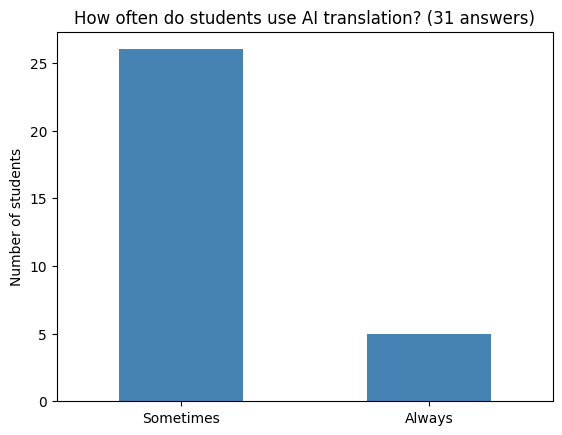

In [3]:
counts = df["ai_frequency"].value_counts(dropna=False)
percentages = (counts / len(df) * 100).round(2)
frequency_table = pd.DataFrame({"n": counts, "percent": percentages})
print(frequency_table)
frequency_table.to_csv("../results/exploration/tables/01_ai_frequency.csv")

# Bar chart (without the missing answer)
df["ai_frequency"].value_counts().plot(kind="bar", color="steelblue")
plt.title("How often do students use AI translation? (31 answers)")
plt.xlabel("")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.savefig("../results/exploration/figures/fig1_ai_frequency.png", dpi=150, bbox_inches="tight")
plt.show()

This matches Table 3.8 of the dissertation (26 sometimes = 81.25%, 5 always = 15.62%, 1 missing = 3.12%, N = 32). Everyone who answered uses AI translation at least sometimes. Only "Sometimes" and "Always" appear in the data,
so I cannot say anything about students who rarely use AI translation.

## 2. Satisfaction and perceived accuracy

In [4]:
# describe() gives count, mean, std, min, quartiles and max in one table
ratings = df[["ai_accuracy_rating", "satisfaction"]].describe().round(2)
print(ratings)
ratings.to_csv("../results/exploration/tables/02_rating_descriptives.csv")

       ai_accuracy_rating  satisfaction
count               32.00         32.00
mean                 6.75          3.28
std                  1.57          0.81
min                  4.00          1.00
25%                  6.00          3.00
50%                  6.00          3.00
75%                  8.00          4.00
max                 10.00          5.00


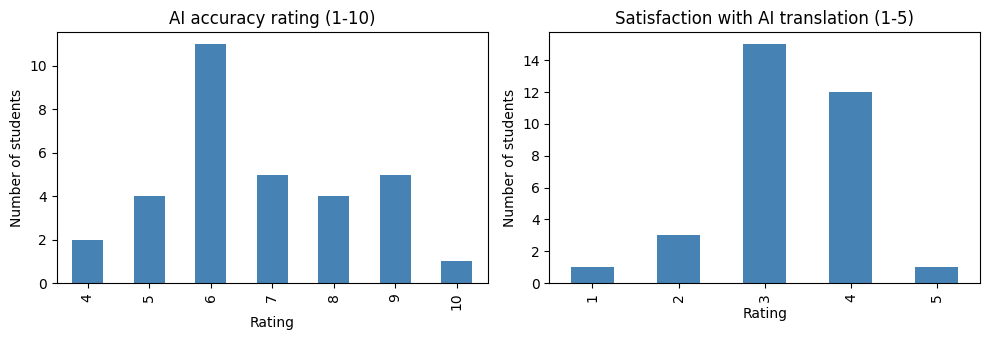

In [5]:
# Two histograms side by side: how many students gave each rating
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

df["ai_accuracy_rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("AI accuracy rating (1-10)")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of students")

df["satisfaction"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Satisfaction with AI translation (1-5)")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Number of students")

plt.tight_layout()
plt.savefig("../results/exploration/figures/fig2_rating_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# How many students are in each satisfaction / accuracy group?
print(df["satisfied"].value_counts())
print()
print(df["accuracy_band"].value_counts())

satisfied
Neutral or dissatisfied (1-3)    19
Satisfied (4-5)                  13
Name: count, dtype: int64

accuracy_band
Medium (6-7)    16
High (8-10)     10
Low (1-5)        6
Name: count, dtype: int64


Ratings are centred on the middle of the scale: accuracy averages about 6.75/10 and satisfaction about 3.3/5.
Only 13 of 32 students (41%) are satisfied (4-5), and one student gave 1/5. This describes a *moderate* view of AI translation, not strong approval or rejection.

## 3. Which method do students prefer, and why?

               n  percent
preference               
Human         17     53.1
AI            13     40.6
Not answered   1      3.1
Depends        1      3.1


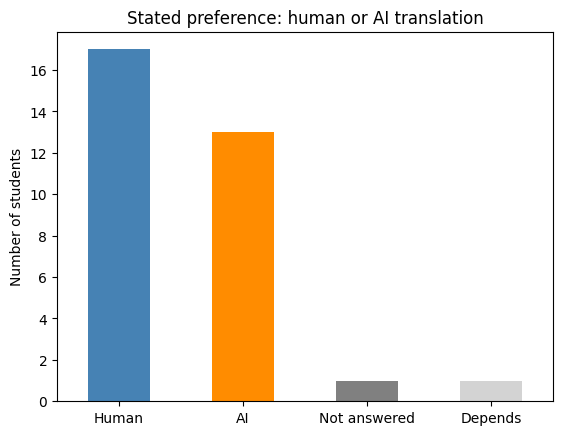

In [7]:
counts = df["preference"].value_counts()
percentages = (counts / len(df) * 100).round(1)
preference_table = pd.DataFrame({"n": counts, "percent": percentages})
print(preference_table)
preference_table.to_csv("../results/exploration/tables/03_preference.csv")

counts.plot(kind="bar", color=["steelblue", "darkorange", "grey", "lightgrey"])
plt.title("Stated preference: human or AI translation")
plt.xlabel("")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.savefig("../results/exploration/figures/fig3_preference.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Which reasons do the two groups give? Count the theme flags created in Notebook 2.
theme_columns = ["theme_speed", "theme_ease_cost", "theme_accuracy", "theme_context_culture"]

theme_counts = df_two.groupby("preference")[theme_columns].sum()
group_sizes = df_two["preference"].value_counts()

# Divide each row by the size of its group to get percentages
theme_percent = (theme_counts.div(group_sizes, axis=0) * 100).round(0)

print("Number of students mentioning each theme:")
print(theme_counts)
print()
print("Percent of each group:")
print(theme_percent)
theme_percent.to_csv("../results/exploration/tables/04_reason_themes_percent.csv")

Number of students mentioning each theme:
            theme_speed  theme_ease_cost  theme_accuracy  theme_context_culture
preference                                                                     
AI                    8                4               1                      2
Human                 2                1               7                      9

Percent of each group:
            theme_speed  theme_ease_cost  theme_accuracy  theme_context_culture
preference                                                                     
AI                 62.0             31.0             8.0                   15.0
Human              12.0              6.0            41.0                   53.0


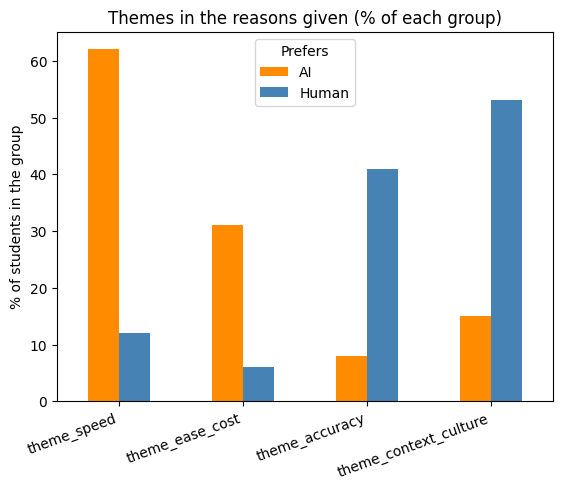

In [9]:
theme_percent.T.plot(kind="bar", color=["darkorange", "steelblue"])
plt.title("Themes in the reasons given (% of each group)")
plt.xlabel("")
plt.ylabel("% of students in the group")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Prefers")
plt.savefig("../results/exploration/figures/fig4_reason_themes.png", dpi=150, bbox_inches="tight")
plt.show()

Students who prefer AI mostly talk about **speed and ease**. Students who prefer human translation mostly talk about **context, culture, meaning and accuracy**.
This is the same pattern as the main thesis conclusion. Because the theme flags come from a simple keyword search, I treat the exact percentages as approximate.

In [10]:
# Speed: which method do students find faster?
counts = df["faster_method"].value_counts()
print(counts)
print()
print("Share of ALL students who say AI is faster:", round(counts["AI"] / len(df) * 100, 1), "%")

faster_method
AI              23
Not answered     5
Unclear          2
Human            2
Name: count, dtype: int64

Share of ALL students who say AI is faster: 71.9 %


## 4. Do ratings differ between students who prefer AI and students who prefer humans?

           ai_accuracy_rating             satisfaction            
                        count  mean   std        count  mean   std
preference                                                        
AI                         13  7.77  1.42           13  3.69  0.63
Human                      17  6.06  1.14           17  3.18  0.64


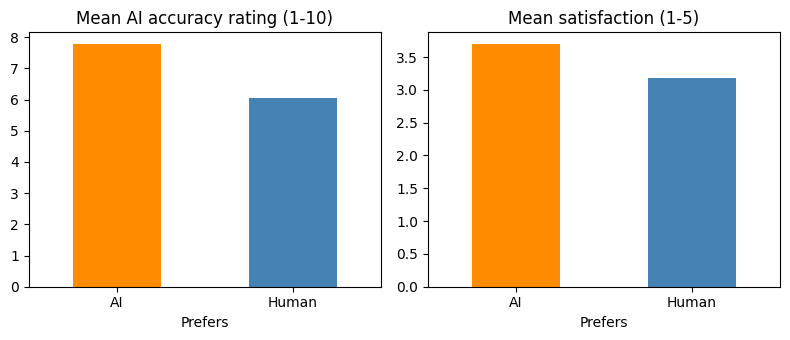

In [11]:
# Average ratings in each preference group
by_preference = df_two.groupby("preference")[["ai_accuracy_rating", "satisfaction"]].agg(["count", "mean", "std"]).round(2)
print(by_preference)
by_preference.to_csv("../results/exploration/tables/05_ratings_by_preference.csv")

# Bar chart of the two means
means = df_two.groupby("preference")[["ai_accuracy_rating", "satisfaction"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
means["ai_accuracy_rating"].plot(kind="bar", ax=axes[0], color=["darkorange", "steelblue"])
axes[0].set_title("Mean AI accuracy rating (1-10)")
axes[1].set_title("Mean satisfaction (1-5)")
means["satisfaction"].plot(kind="bar", ax=axes[1], color=["darkorange", "steelblue"])
for ax in axes:
    ax.set_xlabel("Prefers")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../results/exploration/figures/fig5_ratings_by_preference.png", dpi=150, bbox_inches="tight")
plt.show()

Students who prefer AI rate it as more accurate (about 7.8 vs 6.1) and are more satisfied (3.7 vs 3.2). This is what we would expect: people tend to prefer the tool they find more reliable.
The groups are small (13 and 17), so I describe the difference without claiming that it is statistically proven.

In [12]:
# Usage frequency and ratings
by_frequency = df.groupby("ai_frequency")[["ai_accuracy_rating", "satisfaction"]].agg(["count", "mean"]).round(2)
print(by_frequency)
print()

# Language proficiency and ratings / preference
by_proficiency = df.groupby("proficiency")[["ai_accuracy_rating", "satisfaction"]].agg(["count", "mean"]).round(2)
print(by_proficiency)
print()
print(pd.crosstab(df["proficiency"], df["preference"]))

             ai_accuracy_rating       satisfaction      
                          count  mean        count  mean
ai_frequency                                            
Always                        5  7.60            5  4.00
Sometimes                    26  6.62           26  3.15

            ai_accuracy_rating       satisfaction      
                         count  mean        count  mean
proficiency                                            
B1-B2                       15  6.87           15  3.33
C1-C2                       17  6.65           17  3.24

preference   AI  Depends  Human  Not answered
proficiency                                  
B1-B2         7        0      8             0
C1-C2         6        1      9             1


"Always" users are more satisfied (4.0) than "Sometimes" users (3.15), but only **5 students** are in the "Always" group, so this is a hint, not a result.
Language proficiency makes very little difference to the ratings. In the preference table, AI is chosen by 7 of 15 B1-B2 students and 6 of 17 C1-C2 students; the gap is small.

In [13]:
# Correlations: do students who rate AI accuracy higher also report higher satisfaction?
# Spearman is a good choice for rating scales because it uses the rank order of answers.
columns = ["ai_accuracy_rating", "satisfaction", "ai_frequency_num"]
correlations = df[columns].corr(method="spearman").round(2)
print(correlations)
correlations.to_csv("../results/exploration/tables/06_spearman_correlations.csv")

                    ai_accuracy_rating  satisfaction  ai_frequency_num
ai_accuracy_rating                1.00          0.41              0.24
satisfaction                      0.41          1.00              0.38
ai_frequency_num                  0.24          0.38              1.00


Accuracy and satisfaction have a moderate positive relationship (about 0.41), and so do frequency and satisfaction (about 0.38).
A correlation does not show cause: a student may be satisfied *because* the tool is accurate, or may rate it accurate because they use it a lot and are used to it.

## 5. Willingness to pay for human translation

In [14]:
pay_counts = df["pay_more"].value_counts()
print(pay_counts)
print()

# Row percentages: within each preference group, what share answers Yes / No ...?
pay_table = pd.crosstab(df_two["preference"], df_two["pay_more"])
pay_percent = (pd.crosstab(df_two["preference"], df_two["pay_more"], normalize="index") * 100).round(0)
print(pay_table)
print()
print(pay_percent)
pay_table.to_csv("../results/exploration/tables/07_preference_by_willingness_to_pay.csv")

pay_more
Yes             13
No              10
Conditional      4
Not answered     3
Unclear          2
Name: count, dtype: int64

pay_more    Conditional  No  Not answered  Unclear  Yes
preference                                             
AI                    2   6             1        2    2
Human                 2   3             1        0   11

pay_more    Conditional    No  Not answered  Unclear   Yes
preference                                                
AI                 15.0  46.0           8.0     15.0  15.0
Human              12.0  18.0           6.0      0.0  65.0


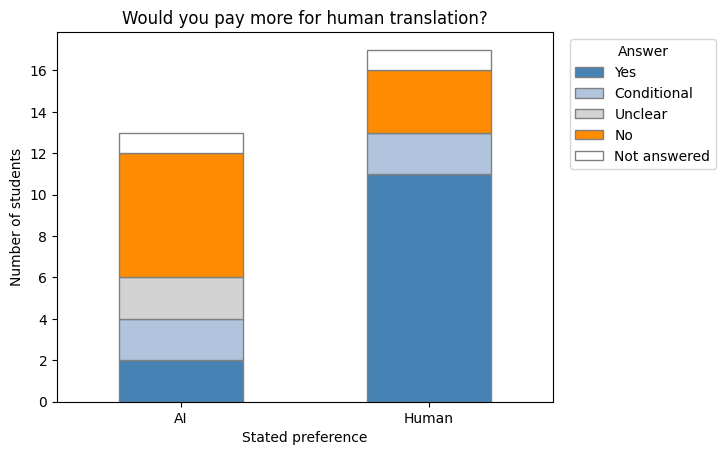

In [15]:
# Stacked bar chart: willingness to pay in each preference group
column_order = ["Yes", "Conditional", "Unclear", "No", "Not answered"]
pay_table = pay_table[column_order]
pay_table.plot(kind="bar", stacked=True, color=["steelblue", "lightsteelblue", "lightgrey", "darkorange", "white"], edgecolor="grey")
plt.title("Would you pay more for human translation?")
plt.xlabel("Stated preference")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.legend(title="Answer", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig("../results/exploration/figures/fig6_willingness_to_pay.png", dpi=150, bbox_inches="tight")
plt.show()

Among the 17 students who prefer human translation, 11 (65%) would pay more for it. Among the 13 who prefer AI, only 2 (15%) would,
and 6 say no; several of them give the fact that AI translation is free as their reason. Several "conditional" answers say they would pay only for important documents or professional situations (for example diplomas).

In [16]:
# Does having really used a human translator change the preference?
print(pd.crosstab(df["used_human"], df["preference"]))

preference    AI  Depends  Human  Not answered
used_human                                    
No             9        1     10             1
Not answered   0        0      1             0
Yes            4        0      6             0


Most students (21 of 31 who answered) have never used a human translation service. Their preference for human translation therefore comes from belief and
perception more than from experience. This matches the thesis topic, which studies perceptions.

## 6. Summary of the exploratory analysis

| Question | What the data show (n = 32) |
|---|---|
| Use of AI translation | 26 students "sometimes" (81%), 5 "always" (16%), 1 missing |
| Perceived accuracy of AI (1-10) | mean 6.75, median 6, SD 1.57 |
| Satisfaction (1-5) | mean 3.28, median 3; 13 students (41%) satisfied (4-5) |
| Preferred method | Human 17 (53%), AI 13 (41%), "depends" 1, missing 1 |
| Faster method | AI for 23 students (72% of all); no answer or unclear for 7 |
| Reasons | AI-preferers: speed (8 of 13) and ease; human-preferers: context/culture (9 of 17) and accuracy (7 of 17) |
| Ratings by preference | AI-preferers rate AI higher (accuracy 7.8 vs 6.1; satisfaction 3.7 vs 3.2) |
| Willingness to pay | Yes 13, conditional 4, no 10, unclear 2, missing 3; 65% of human-preferers say yes against 15% of AI-preferers |

**What I conclude:** in this group, AI translation is seen as fast and convenient, while human translation is trusted for context, culture and accuracy.
Most students give AI translation a middle rating, and half of them would pay for a human translator, mainly for important or professional texts.
Most of them have never used a human translation service, so their views rest more on perception than on experience.

**Limits:** 32 students, a convenience sample, mostly women and mostly linguistics students; keyword-based theme counts are approximate;
the "Always" group has only 5 students; the accuracy and satisfaction questions compare AI with human translation in a single rating, so they are relative judgements.
I therefore describe patterns and do not claim statistical proof.